# 01 — EDA & Data Cleaning
**Lumen Data Science — Cross-Sell & Up-Sell Prediction**

Reads the raw dataset (UTF-16, pipe-separated) and produces the canonical clean file used by every downstream notebook.

Steps:
1. **Load** — convert encoding, parse dates, drop redundant columns
2. **EDA** — null/zero analysis, cardinality checks
3. **Row filtering** — remove missing key identifiers, SAMPLE/slash item codes, negative prices/quantities, garbage cost records (cost > 20× price)
4. **Imputation** — fill categorical nulls with `'Unknown'`, recalculate `GM%` where price and cost are both available

**Output:** `data/processed/data_clean_final.csv`

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
import os

pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', '{:.4f}'.format)
plt.rcParams['figure.figsize'] = (12, 5)
sns.set_theme(style='whitegrid')

print('Libraries loaded ✓')

Libraries loaded ✓


---
## 1. Učitavanje podataka


In [2]:
import os

raw_path = '../data/raw/LUMEN_DS.csv'
converted_path = '../data/raw/data.csv'

if not os.path.exists(converted_path):
    with open(raw_path, 'r', encoding='utf-16') as file:
        data = file.read()
    
    data = data.replace('"', '')
    
    with open(converted_path, 'w', encoding='utf-8') as file:
        file.write(data)
    
    print('Konverzija gotova -> data.csv')
else:
    print('data.csv već postoji, preskačem konverziju')

data.csv već postoji, preskačem konverziju


In [3]:
DATE_COLS = [
    'Invoice Date',
    'Order Date',
    'Customer First Invoice Date',
    'Price last modified date in the ERP',
    'Born on date'
]

df_raw = pd.read_csv(
    '../data/raw/data.csv',
    encoding='utf-8',
    sep='|',
    low_memory=False,
    parse_dates=DATE_COLS
)

print(f'Shape: {df_raw.shape}')
print(f'Redova: {df_raw.shape[0]:,} | Stupaca: {df_raw.shape[1]}')
df_raw.head(3)

Shape: (1294962, 33)
Redova: 1,294,962 | Stupaca: 33


,Manufacturing Region,Manufacturing Location Code,Intercompany,CustomerID,Customer industry,Customer Region,Customer First Invoice Date,Top Customer Group,Item Code,Product family,Product group,Price last modified date in the ERP,Born on date,Make vs Buy,Sales Channel - Internal,Sales Channel - External,Sales Channel - Grouping,Invoice Date,Invoice #,Invoice Line #,Order Date,Order #,Order Line #,Invoiced qty (shipped),Ordered qty,Invoiced price,Invoiced price (TX),Cost of part,Material cost of part,Labor cost of part,Overhead cost of part,GM%,# of unique products on a quote
0,North America,N7,YES,224224,IC000,Asia,2009-06-26,OTHER,054501,PF002,NaN,NaT,2012-02-13,BUY,099,099,NaN,2019-08-06,16782381,18645771,2019-08-05,32606.0000,15791584.0000,499.0000,499.0000,0.3900,0.3900,0.4173,0.3900,0.0000,0.0000,-0.0700,1.0000
1,North America,N7,NO,230494,IC012,North America,2007-08-08,OTHER,034903,PF002,PC026,2020-06-22,2009-12-31,BUY,900,900,NaN,2019-11-26,16808190,18670413,2019-11-24,82915.0000,15806968.0000,1000.0000,1000.0000,0.1400,0.1400,0.0257,0.0240,0.0000,0.0000,0.8164,3.0000
2,Asia,N13,YES,235861,IC000,North America,2008-02-07,OTHER,057280,PF002,NaN,NaT,2017-01-03,MANUFACTURED,RS-NH,RS-NH,NaN,2019-09-24,16790722,18655474,2019-09-03,32787.0000,15795161.0000,3.0000,3.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,NaN,14.0000


---
## 2. Osnovni pregled — dtypes, nullovi, unike

In [4]:
# Pregled svakog stupca: dtype, % nullova, broj unikatnih vrijednosti
summary = pd.DataFrame({
    'dtype': df_raw.dtypes,
    'null_count': df_raw.isnull().sum(),
    'null_%': (df_raw.isnull().sum() / len(df_raw) * 100).round(2),
    'n_unique': df_raw.nunique(),
    'sample_value': df_raw.iloc[0],
    'zero': df_raw.eq(0).sum(),
    'zero_%': (df_raw.eq(0).sum() / len(df_raw) * 100).round(2)
})
display(summary)

,dtype,null_count,null_%,n_unique,sample_value,zero,zero_%
Manufacturing Region,object,40509,3.1300,3,North America,0,0.0000
Manufacturing Location Code,object,39959,3.0900,29,N7,0,0.0000
Intercompany,object,0,0.0000,2,YES,0,0.0000
CustomerID,int64,0,0.0000,12214,224224,0,0.0000
Customer industry,object,0,0.0000,15,IC000,0,0.0000
Customer Region,object,103,0.0100,3,Asia,0,0.0000
Customer First Invoice Date,datetime64[ns],0,0.0000,4232,2009-06-26 00:00:00,0,0.0000
Top Customer Group,object,0,0.0000,2,OTHER,0,0.0000
Item Code,object,55,0.0000,63019,054501,0,0.0000
Product family,object,0,0.0000,3,PF002,0,0.0000


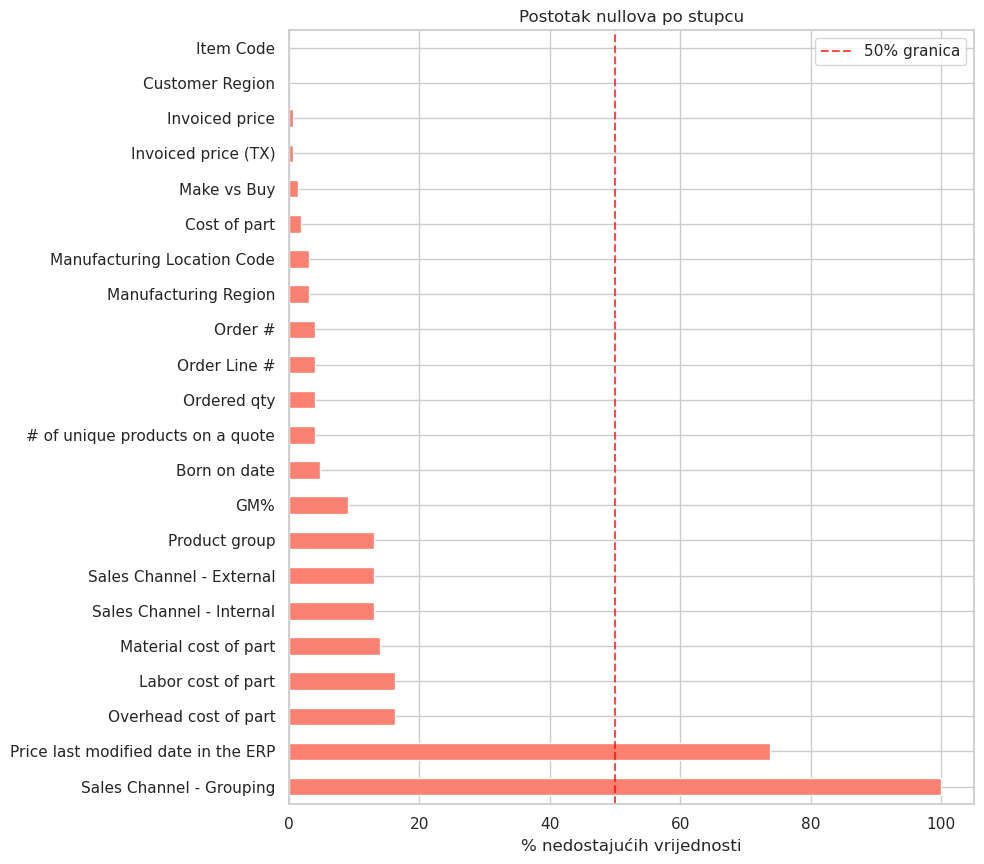

In [5]:
# Vizualizacija % nullova po stupcu
null_pct = (df_raw.isnull().sum() / len(df_raw) * 100).sort_values(ascending=False)
null_pct = null_pct[null_pct > 0]

if len(null_pct) > 0:
    fig, ax = plt.subplots(figsize=(10, max(4, len(null_pct) * 0.4)))
    null_pct.plot(kind='barh', ax=ax, color='salmon')
    ax.set_xlabel('% nedostajućih vrijednosti')
    ax.set_title('Postotak nullova po stupcu')
    ax.axvline(50, color='red', linestyle='--', alpha=0.7, label='50% granica')
    ax.legend()
    plt.tight_layout()
    plt.show()
else:
    print('Nema nullova — provjeri jesu li prazni stringovi umjesto NaN!')

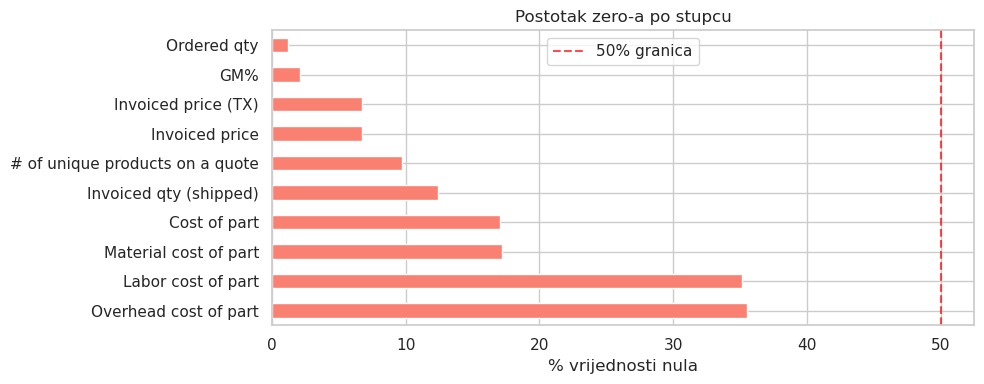

In [6]:
# Vizualizacija % zero-a po stupcu
zero_pct = (df_raw.eq(0).sum() / len(df_raw) * 100).sort_values(ascending=False)
zero_pct = zero_pct[zero_pct > 0]

if len(zero_pct) > 0:
    fig, ax = plt.subplots(figsize=(10, max(4, len(zero_pct) * 0.4)))
    zero_pct.plot(kind='barh', ax=ax, color='salmon')
    ax.set_xlabel('% vrijednosti nula')
    ax.set_title('Postotak zero-a po stupcu')
    ax.axvline(50, color='red', linestyle='--', alpha=0.7, label='50% granica')
    ax.legend()
    plt.tight_layout()
    plt.show()
else:
    print('Nema zero-a!')

In [7]:
# Provjeri prazne stringove (čest problem u ovom datasetu)
empty_str = (df_raw == '').sum()
empty_str = empty_str[empty_str > 0]
print('Stupci s praznim stringovima:')
print(empty_str.sort_values(ascending=False))

Stupci s praznim stringovima:
Series([], dtype: int64)


---
## 3. Uklanjanje stupaca (nastavak od cleaner.py)

Prijateljev cleaner.py već je uklonio stupce koji su redudantni ili previše granularni.
Ovdje razmatramo treba li još nešto ukloniti.

In [8]:
# Stupci koje je cleaner.py uklonio, ali malo editano
already_dropped = [
    'Invoice Line #', 'Order Date',
    'Material cost of part', 'Labor cost of part', 'Overhead cost of part',
    'Sales Channel - Grouping', 'Born on date',
    'Price last modified date in the ERP', 'Order Line #', 'Order #', '# of unique products on a quote'
]

# Primijeni drop (samo ako stupci postoje u df_raw)
cols_to_drop = [c for c in already_dropped if c in df_raw.columns]
df = df_raw.drop(columns=cols_to_drop)
print(f'Nakon inicijalnog dropa: {df.shape}')

Nakon inicijalnog dropa: (1294962, 22)


In [9]:
# --- ANALIZA PREOSTALIH STUPACA ---
# Pogledaj kardinalnost kategoričkih stupaca
cat_cols = df.select_dtypes(include='object').columns.tolist()

for col in cat_cols:
    vc = df[col].value_counts(dropna=False)
    print(f'\n=== {col} ({df[col].nunique()} unikatnih) ===')
    print(vc.head(10))


=== Manufacturing Region (3 unikatnih) ===
Manufacturing Region
North America    734815
Asia             464038
Europe            55600
NaN               40509
Name: count, dtype: int64

=== Manufacturing Location Code (29 unikatnih) ===
Manufacturing Location Code
B6     199828
B8     151245
N13    124771
B77    103285
B20     99905
B70     89945
L1      67043
L2      59951
B3      54164
B76     46967
Name: count, dtype: int64

=== Intercompany (2 unikatnih) ===
Intercompany
NO     1103993
YES     190969
Name: count, dtype: int64

=== Customer industry (15 unikatnih) ===
Customer industry
IC000    453233
IC007    183975
IC008    175248
IC003    103123
IC005     96904
IC004     64220
IC011     59069
IC010     49535
IC009     37024
IC002     28634
Name: count, dtype: int64

=== Customer Region (3 unikatnih) ===
Customer Region
North America    773408
Asia             439883
Europe            81568
NaN                 103
Name: count, dtype: int64

=== Top Customer Group (2 unikatnih) =

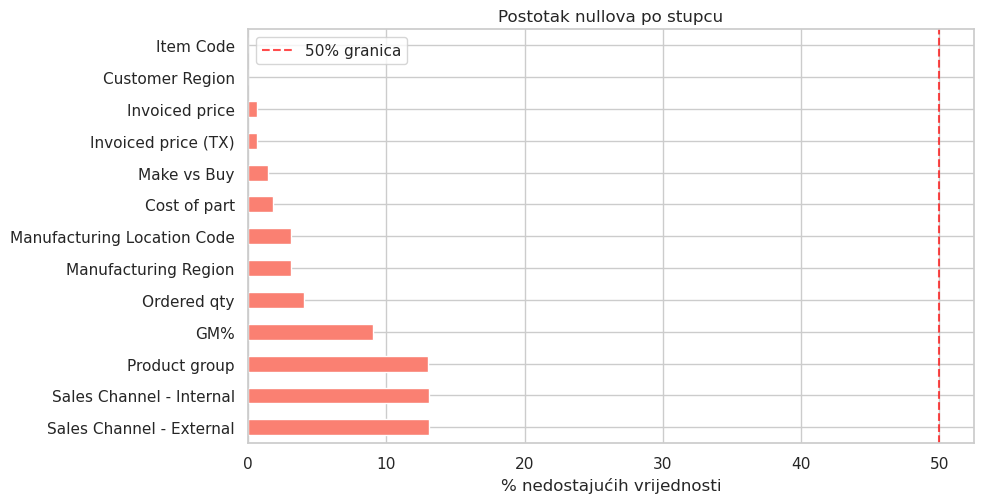

In [10]:
# Vizualizacija % nullova po stupcu
null_pct = (df.isnull().sum() / len(df) * 100).sort_values(ascending=False)
null_pct = null_pct[null_pct > 0]

if len(null_pct) > 0:
    fig, ax = plt.subplots(figsize=(10, max(4, len(null_pct) * 0.4)))
    null_pct.plot(kind='barh', ax=ax, color='salmon')
    ax.set_xlabel('% nedostajućih vrijednosti')
    ax.set_title('Postotak nullova po stupcu')
    ax.axvline(50, color='red', linestyle='--', alpha=0.7, label='50% granica')
    ax.legend()
    plt.tight_layout()
    plt.show()
else:
    print('Nema nullova — provjeri jesu li prazni stringovi umjesto NaN!')

In [11]:
# DECISION: filter out Intercompany=YES (intra-corp sales, not real customers)
df_external = df[df['Intercompany'] == 'NO'].copy()
print(f'After filtering Intercompany=YES: {df_external.shape}')

After filtering Intercompany=YES: (1103993, 22)


---
## 4. Čišćenje redova

In [12]:
df_4 = df_external.copy()

print(df_4.columns.tolist())

['Manufacturing Region', 'Manufacturing Location Code', 'Intercompany', 'CustomerID', 'Customer industry', 'Customer Region', 'Customer First Invoice Date', 'Top Customer Group', 'Item Code', 'Product family', 'Product group', 'Make vs Buy', 'Sales Channel - Internal', 'Sales Channel - External', 'Invoice Date', 'Invoice #', 'Invoiced qty (shipped)', 'Ordered qty', 'Invoiced price', 'Invoiced price (TX)', 'Cost of part', 'GM%']


In [13]:
# Pregled svakog stupca: dtype, % nullova, broj unikatnih vrijednosti
summary_4 = pd.DataFrame({
    'dtype': df_4.dtypes,
    'null_count': df_4.isnull().sum(),
    'null_%': (df_4.isnull().sum() / len(df_4) * 100).round(2),
    'n_unique': df_4.nunique(),
    'sample_value': df_4.iloc[0],
    'zero': df_4.eq(0).sum(),
    'zero_%': (df_4.eq(0).sum() / len(df_4) * 100).round(2)
})
display(summary_4)

,dtype,null_count,null_%,n_unique,sample_value,zero,zero_%
Manufacturing Region,object,36852,3.3400,3,North America,0,0.0000
Manufacturing Location Code,object,36310,3.2900,29,N7,0,0.0000
Intercompany,object,0,0.0000,1,NO,0,0.0000
CustomerID,int64,0,0.0000,11864,230494,0,0.0000
Customer industry,object,0,0.0000,15,IC012,0,0.0000
Customer Region,object,96,0.0100,3,North America,0,0.0000
Customer First Invoice Date,datetime64[ns],0,0.0000,4204,2007-08-08 00:00:00,0,0.0000
Top Customer Group,object,0,0.0000,2,OTHER,0,0.0000
Item Code,object,50,0.0000,56181,034903,0,0.0000
Product family,object,0,0.0000,3,PF002,0,0.0000


In [14]:
# 4a. Ukloni redove bez ključnih identifikatora
before = len(df_4)
df_4 = df_4.dropna(subset=['Item Code', 'CustomerID'])
df_4 = df_4[df_4['CustomerID'] != -99]
print(f'Uklonjeno zbog null ključnih stupaca i customerID=-99: {before - len(df_4)} redova')

Uklonjeno zbog null ključnih stupaca i customerID=-99: 80 redova


In [15]:
bad_price = df_4['Invoiced price'].isna() | (df_4['Invoiced price'] == 0)
print(f'Ukupno redova bez prave cijene: {bad_price.sum():,}')
print(f'  - null: {df_4["Invoiced price"].isna().sum():,}')
print(f'  - zero: {(df_4["Invoiced price"] == 0).sum():,}')
print(f'  - negativne (zasebno rješavamo): {(df_4["Invoiced price"] < 0).sum():,}')
print(f'\nTo je {bad_price.mean()*100:.1f}% dataseta')
 

Ukupno redova bez prave cijene: 69,287
  - null: 8,518
  - zero: 60,769
  - negativne (zasebno rješavamo): 549

To je 6.3% dataseta


In [16]:
sample_slash_mask = df_4['Item Code'].str.contains(r'SAMPLE|^/', na=False)
 
print('=== SAMPLE i slash (/) item codeovi — pregled ===\n')
print(f'Ukupno redova: {sample_slash_mask.sum():,}')
print(f'Unique item codeova: {df_4[sample_slash_mask]["Item Code"].nunique()}')
 
# Koliko ih ima pravu cijenu, koliko ne?
ss_with_price = (df_4[sample_slash_mask]['Invoiced price'] > 0).sum()
ss_without_price = (
    df_4[sample_slash_mask]['Invoiced price'].isna() | 
    (df_4[sample_slash_mask]['Invoiced price'] == 0)
).sum()
print(f'\nRedova s cijenom > 0: {ss_with_price:,} ({ss_with_price/sample_slash_mask.sum()*100:.1f}%)')
print(f'Redova s null/zero cijenom: {ss_without_price:,} ({ss_without_price/sample_slash_mask.sum()*100:.1f}%)')
 
# Breakdown po item codeu
ss_stats = (
    df_4[sample_slash_mask]
    .groupby('Item Code')
    .agg(
        total=('Invoiced price', 'size'),
        has_price=('Invoiced price', lambda x: (x > 0).sum())
    )
)
ss_stats['pct_with_price'] = (ss_stats['has_price'] / ss_stats['total'] * 100).round(1)
ss_stats = ss_stats.sort_values('total', ascending=False)
 
print('\nBreakdown po item codeu:')
display(ss_stats)

=== SAMPLE i slash (/) item codeovi — pregled ===

Ukupno redova: 16,533
Unique item codeova: 92

Redova s cijenom > 0: 1,702 (10.3%)
Redova s null/zero cijenom: 14,831 (89.7%)

Breakdown po item codeu:


,total,has_price,pct_with_price
Item Code,,,
/C,8319,0,0.0000
/LTI,4251,0,0.0000
SAMPLE-MPCS,970,442,45.6000
SAMPLE-EACH,660,198,30.0000
BOY485-SAMPLES,469,44,9.4000
...,...,...,...
SAMPLE-EZ BRA,1,0,0.0000
"SAMPLE-CONVERTERS, INC.",1,0,0.0000
SAMPLE-NipEAZE,1,1,100.0000


In [17]:
before = len(df_4)
df_4 = df_4[~df_4['Item Code'].str.contains(r'SAMPLE|^/', na=False)]
print(f'Izbačeno SAMPLE/slash item codeova: {before - len(df_4)} redova')
print(f'Shape nakon: {df_4.shape}')
# izbacujemo item codeove koji pocinju s SAMPLE i /, oni ne bi trebali biti u finalnom datasetu po odgovoru Atomic Intelligence-a

Izbačeno SAMPLE/slash item codeova: 16533 redova
Shape nakon: (1087380, 22)


In [18]:
# Za SVAKI item code: koliki % svih redova ima pravu cijenu?
item_stats = df_4.groupby('Item Code').agg(
    total=('Invoiced price', 'size'),
    has_price=('Invoiced price', lambda x: (x > 0).sum())
)
item_stats['pct'] = item_stats['has_price'] / item_stats['total']
 
# Sensitivity — koliko redova spašavamo po pragu?
print('=== Sensitivity check — threshold vs. broj redova ===\n')
for t in [0.1, 0.3, 0.5, 0.7, 0.9]:
    imputable = item_stats[item_stats['pct'] >= t].index
    n_saved = df_4[bad_price & df_4['Item Code'].isin(imputable)].shape[0]
    n_deleted = bad_price.sum() - n_saved
    n_items_saved = df_4.loc[bad_price & df_4['Item Code'].isin(imputable), 'Item Code'].nunique()
    n_items_deleted = df_4.loc[bad_price & ~df_4['Item Code'].isin(imputable), 'Item Code'].nunique()
    print(f'  Threshold {t:.0%}: impute {n_saved:>6,} redova ({n_items_saved:>3} itema) | '
          f'delete {n_deleted:>6,} redova ({n_items_deleted:>3} itema)')

=== Sensitivity check — threshold vs. broj redova ===



/tmp/ipykernel_136283/2904989362.py:12: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  n_saved = df_4[bad_price & df_4['Item Code'].isin(imputable)].shape[0]


  Threshold 10%: impute 17,594 redova (5380 itema) | delete 51,693 redova (4064 itema)


/tmp/ipykernel_136283/2904989362.py:12: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  n_saved = df_4[bad_price & df_4['Item Code'].isin(imputable)].shape[0]


  Threshold 30%: impute 14,739 redova (5298 itema) | delete 54,548 redova (4146 itema)


...

  Threshold 50%: impute 12,390 redova (5122 itema) | delete 56,897 redova (4322 itema)


/tmp/ipykernel_136283/2904989362.py:12: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  n_saved = df_4[bad_price & df_4['Item Code'].isin(imputable)].shape[0]


  Threshold 70%: impute  9,394 redova (4022 itema) | delete 59,893 redova (5422 itema)


/tmp/ipykernel_136283/2904989362.py:12: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  n_saved = df_4[bad_price & df_4['Item Code'].isin(imputable)].shape[0]


  Threshold 90%: impute  4,731 redova (2496 itema) | delete 64,556 redova (6948 itema)


In [19]:
THRESHOLD = 0.5  # <-- prilagodi nakon sensitivity checka
# ili bi cak stavio 0.7
 
imputable_items = item_stats[item_stats['pct'] >= THRESHOLD].index
 
# Medijan SAMO od pozitivnih cijena
median_price = (
    df_4[df_4['Invoiced price'] > 0]
    .groupby('Item Code')['Invoiced price']
    .median()
)
 
# Impute gdje možemo
impute_mask = bad_price & df_4['Item Code'].isin(imputable_items)
df_4.loc[impute_mask, 'Invoiced price'] = (
    df_4.loc[impute_mask, 'Item Code'].map(median_price)
)
print(f'Imputirano: {impute_mask.sum():,} redova ({df_4.loc[impute_mask, "Item Code"].nunique()} itema)')
 
# Obriši gdje ne možemo
delete_mask = bad_price & ~df_4['Item Code'].isin(imputable_items)
print(f'Brisanje: {delete_mask.sum():,} redova ({df_4.loc[delete_mask, "Item Code"].nunique()} itema)')
print(f'\nTop 20 obrisanih item codeova:')
print(df_4[delete_mask]['Item Code'].value_counts().head(20))
 
before = len(df_4)
df_4 = df_4[~delete_mask]
print(f'\nShape: {before:,} → {len(df_4):,} (obrisano {before - len(df_4):,})')

Imputirano: 12,390 redova (5122 itema)
Brisanje: 42,066 redova (4322 itema)

Top 20 obrisanih item codeova:
Item Code
TRANSPORTKOSTEN       7815
SMSKID                3695
LGMC-000203            652
AUSFA                  401
BOY485-LASER           325
*200005                295
BOY485-JETSON          186
DEL449-YC553-1         165
NEUBS                  156
PROGRAMM               155
DEL449-1051501-9       126
DEL449-1888601         126
DEL449-31FGN-1         126
DEL449-B1803801        125
F999-000001            123
DEL449-7B174FR-2       117
DEL449-3MT28-701       115
DEL449-B1928201        109
ZUSATZAUFWANDKTR50     109
DEL449-1804401         108
Name: count, dtype: int64

Shape: 1,087,380 → 1,045,314 (obrisano 42,066)


/tmp/ipykernel_136283/2182481718.py:24: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  print(df_4[delete_mask]['Item Code'].value_counts().head(20))
/tmp/ipykernel_136283/2182481718.py:27: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  df_4 = df_4[~delete_mask]


In [20]:
# Za Invoiced price < 0
print(f'Redova s Invoiced price < 0: {(df_4["Invoiced price"] < 0).sum()}')
display(df_4[df_4['Invoiced price'] < 0].head(10))

Redova s Invoiced price < 0: 549


,Manufacturing Region,Manufacturing Location Code,Intercompany,CustomerID,Customer industry,Customer Region,Customer First Invoice Date,Top Customer Group,Item Code,Product family,Product group,Make vs Buy,Sales Channel - Internal,Sales Channel - External,Invoice Date,Invoice #,Invoiced qty (shipped),Ordered qty,Invoiced price,Invoiced price (TX),Cost of part,GM%
29223,North America,N7,NO,216863,IC008,North America,2020-01-10,OTHER,032647,PF002,PC013,BUY,AL-01,AL-01,2020-01-10,4777653,24.6000,24.6000,-0.0102,-0.0102,1.9863,195.7353
33373,NaN,NaN,NO,279825,IC003,North America,2003-07-16,OTHER,46000,PF000,NaN,MANUFACTURED,DEW-NC,DEW-NC,2018-10-19,1208666,1.0000,1.0000,-36.6000,-36.6000,0.0000,1.0000
33374,NaN,NaN,NO,287422,IC003,North America,2003-07-08,OTHER,46000,PF000,NaN,MANUFACTURED,SA-NC,SA-NC,2018-11-05,1161143,1.0000,1.0000,-9.1900,-9.1900,0.0000,1.0000
33531,NaN,NaN,NO,287422,IC003,North America,2003-07-08,OTHER,46000,PF000,NaN,MANUFACTURED,SA-NC,SA-NC,2018-10-16,1161501,1.0000,1.0000,-9.6100,-9.6100,0.0000,1.0000
33532,NaN,NaN,NO,285880,IC000,North America,2017-11-02,OTHER,46000,PF000,NaN,MANUFACTURED,H,H,2018-11-27,1335118,1.0000,1.0000,-81.6600,-81.6600,0.0000,1.0000
33533,NaN,NaN,NO,284197,IC003,North America,2006-01-25,OTHER,46000,PF000,NaN,MANUFACTURED,DG-NC,DG-NC,2018-03-15,1227710,1.0000,1.0000,-8.7200,-8.7200,0.0000,1.0000
33542,NaN,NaN,NO,281386,IC003,North America,2011-08-09,OTHER,46000,PF000,NaN,MANUFACTURED,JG,JG,2019-03-29,1314266,1.0000,1.0000,-13.0100,-13.0100,0.0000,1.0000
33543,NaN,NaN,NO,285396,IC003,North America,2011-10-31,OTHER,46000,PF000,NaN,MANUFACTURED,TW,TW,2018-12-20,1317780,1.0000,1.0000,-62.8400,-62.8400,0.0000,1.0000
33545,NaN,NaN,NO,284294,IC003,North America,2004-06-16,OTHER,46000,PF000,NaN,MANUFACTURED,H,H,2018-07-11,1236921,1.0000,1.0000,-11.3900,-11.3900,0.0000,1.0000
33546,NaN,NaN,NO,285878,IC000,North America,2017-10-10,OTHER,46000,PF000,NaN,MANUFACTURED,H,H,2018-07-26,1334956,1.0000,1.0000,-42.8100,-42.8100,0.0000,1.0000


In [21]:
# Provjeri što je item code 46000
print(df_4[df_4['Item Code'] == '46000'][['Product family', 'Product group', 'Make vs Buy', 'Sales Channel - Internal']].value_counts().head(10))

# Ima li 46000 i normalnih (pozitivnih) transakcija?
print(f'\n46000 redova s cijenom > 0: {(df_4[df_4["Item Code"] == "46000"]["Invoiced price"] > 0).sum()}')
print(f'46000 redova s cijenom < 0: {(df_4[df_4["Item Code"] == "46000"]["Invoiced price"] < 0).sum()}')

# Kanal raspodjela negativnih
print('\nKanal raspodjela negativnih cijena:')
print(df_4[df_4['Invoiced price'] < 0]['Sales Channel - Internal'].value_counts().head(10))

Series([], Name: count, dtype: int64)

46000 redova s cijenom > 0: 2253
46000 redova s cijenom < 0: 508

Kanal raspodjela negativnih cijena:
Sales Channel - Internal
H         128
TW         84
JG         81
SA         49
DEW        35
DAO-NC     32
DEW-NC     28
ES         17
MW         15
DG         14
Name: count, dtype: int64


In [22]:
# Što su pozitivne 46000 transakcije
display(df_4[
    (df_4['Item Code'] == '46000') & 
    (df_4['Invoiced price'] > 0)
].head(5))

,Manufacturing Region,Manufacturing Location Code,Intercompany,CustomerID,Customer industry,Customer Region,Customer First Invoice Date,Top Customer Group,Item Code,Product family,Product group,Make vs Buy,Sales Channel - Internal,Sales Channel - External,Invoice Date,Invoice #,Invoiced qty (shipped),Ordered qty,Invoiced price,Invoiced price (TX),Cost of part,GM%
33365,NaN,NaN,NO,106730,IC009,North America,2016-09-08,OTHER,46000,PF000,NaN,MANUFACTURED,NP,NP,2020-01-31,1111295,1.0000,1.0000,15.3800,15.3800,0.0000,1.0000
33366,NaN,NaN,NO,106730,IC009,North America,2016-09-08,OTHER,46000,PF000,NaN,MANUFACTURED,NP,NP,2019-05-30,1109605,1.0000,1.0000,123.0900,123.0900,0.0000,1.0000
33367,NaN,NaN,NO,106730,IC009,North America,2016-09-08,OTHER,46000,PF000,NaN,MANUFACTURED,NP,NP,2019-05-30,1109604,1.0000,1.0000,28.3400,28.3400,0.0000,1.0000
33370,NaN,NaN,NO,289929,IC003,North America,2019-03-08,OTHER,46000,PF000,NaN,MANUFACTURED,NaN,NaN,2019-03-21,1335516,0.0000,1.0000,11.7700,11.7700,11.7700,0.0000
33389,NaN,NaN,NO,283252,IC003,North America,2014-04-21,OTHER,46000,PF000,NaN,MANUFACTURED,JG,JG,2019-05-22,1124620,0.0000,1.0000,111.3900,111.3900,66.3900,0.4040


In [23]:
before = len(df_4)
df_4 = df_4[df_4['Invoiced price'] >= 0]
print(f'Obrisano negativnih: {before - len(df_4)} redova')
print(f'Shape nakon: {df_4.shape}')

Obrisano negativnih: 549 redova
Shape nakon: (1044765, 22)


In [24]:
print(f'Shape: {df_4.shape}')
print(f'\nNullovi:')
print(df_4.isnull().sum()[df_4.isnull().sum() > 0])
print(f'\nPrazni stringovi:')
empty = (df_4 == '').sum()
print(empty[empty > 0])

Shape: (1044765, 22)

Nullovi:
Manufacturing Region           23515
Manufacturing Location Code    22973
Customer Region                   62
Product group                  47325
Make vs Buy                     3547
Sales Channel - Internal       22062
Sales Channel - External       22062
Ordered qty                    27156
Invoiced price (TX)                2
Cost of part                   20927
GM%                            32166
dtype: int64

Prazni stringovi:
Series([], dtype: int64)


In [25]:
print(f'Redova s Invoiced qty <= 0: {(df_4["Invoiced qty (shipped)"] <= 0).sum()}')
print(f'Redova s Invoiced qty < 0: {(df_4["Invoiced qty (shipped)"] < 0).sum()}')
print(f'Redova s Invoiced qty == 0: {(df_4["Invoiced qty (shipped)"] == 0).sum()}')

display(df_4[df_4['Invoiced qty (shipped)'] <= 0].head(5))

Redova s Invoiced qty <= 0: 114437
Redova s Invoiced qty < 0: 6
Redova s Invoiced qty == 0: 114431


,Manufacturing Region,Manufacturing Location Code,Intercompany,CustomerID,Customer industry,Customer Region,Customer First Invoice Date,Top Customer Group,Item Code,Product family,Product group,Make vs Buy,Sales Channel - Internal,Sales Channel - External,Invoice Date,Invoice #,Invoiced qty (shipped),Ordered qty,Invoiced price,Invoiced price (TX),Cost of part,GM%
129,North America,B20,NO,285757,IC003,North America,2016-02-26,OTHER,2-125-000-15776,PF001,PC010,MANUFACTURED,SA,SA,2018-10-19,1332363,0.0000,210.0000,11.7600,11.7600,8.2282,0.3003
130,North America,B20,NO,285757,IC003,North America,2016-02-26,OTHER,2-125-000-15776,PF001,PC010,MANUFACTURED,SA,SA,2018-09-24,1332362,0.0000,210.0000,11.7600,11.7600,8.2282,0.3003
132,North America,B20,NO,285396,IC003,North America,2011-10-31,OTHER,2-125-000-16104,PF001,PC001,MANUFACTURED,DGIFT,DGIFT,2020-03-12,17124990,0.0000,3.4000,0.3300,0.3300,0.1906,0.4224
133,North America,B20,NO,285396,IC003,North America,2011-10-31,OTHER,2-125-000-16104,PF001,PC001,MANUFACTURED,DGIFT,DGIFT,2020-03-12,17124991,0.0000,3.4000,0.3300,0.3300,0.1906,0.4224
136,North America,B20,NO,288928,IC003,North America,2008-04-24,OTHER,2-125-000-16179,PF001,PC010,MANUFACTURED,SA,SA,2019-04-26,1271002,0.0000,12.0000,35.7700,35.7700,19.1147,0.4656


In [26]:
print(f'Redova s Ordered qty <= 0: {(df_4["Ordered qty"] <= 0).sum()}')
print(f'Redova s Ordered qty < 0: {(df_4["Ordered qty"] < 0).sum()}')
print(f'Redova s Ordered qty == 0: {(df_4["Ordered qty"] == 0).sum()}')

display(df_4[df_4['Ordered qty'] <= 0].head(5))

Redova s Ordered qty <= 0: 2771
Redova s Ordered qty < 0: 5
Redova s Ordered qty == 0: 2766


,Manufacturing Region,Manufacturing Location Code,Intercompany,CustomerID,Customer industry,Customer Region,Customer First Invoice Date,Top Customer Group,Item Code,Product family,Product group,Make vs Buy,Sales Channel - Internal,Sales Channel - External,Invoice Date,Invoice #,Invoiced qty (shipped),Ordered qty,Invoiced price,Invoiced price (TX),Cost of part,GM%
666,North America,B20,NO,285751,IC003,North America,2016-01-28,OTHER,2-125-000-18620,PF001,PC010,MANUFACTURED,TW,TW,2019-08-22,1332254,0.0000,0.0000,55.0000,55.0000,16.1005,0.7073
1219,Asia,B77,NO,20750,IC007,Asia,2013-12-10,OTHER,DEL449-4758U37CI,PF001,PC010,MANUFACTURED,B318,B318,2018-12-27,13582500,500.0000,0.0000,0.4505,0.4505,0.2720,0.3962
3327,Asia,B76,NO,19415,IC008,Asia,2014-06-09,OTHER,DEL449-5340A08CI,PF001,PC010,MANUFACTURED,B318,B318,2018-08-20,15356136,7263.0000,0.0000,0.3703,0.3703,0.2753,0.2565
6609,North America,B20,NO,285154,IC003,North America,2009-08-06,OTHER,2-160-100-16188,PF001,PC001,MANUFACTURED,SA,SA,2019-08-15,1300116,0.0000,0.0000,490.0000,490.0000,304.3115,0.3790
6610,North America,B20,NO,285154,IC003,North America,2009-08-06,OTHER,2-160-100-16188,PF001,PC001,MANUFACTURED,SA,SA,2019-07-11,1300049,0.0000,0.0000,490.0000,490.0000,304.3115,0.3790


In [27]:
# Jesu li qty=0 redovi isporučeni ali bez zabilježene količine?
zero_qty = df_4[df_4['Invoiced qty (shipped)'] == 0]

# Imaju li normalnu cijenu?
print(f'% s cijenom > 0: {(zero_qty["Invoiced price"] > 0).mean()*100:.1f}%')

# Imaju li Ordered qty > 0?
print(f'% s Ordered qty > 0: {(zero_qty["Ordered qty"] > 0).mean()*100:.1f}%')

# Koliko jedinstvenih kupaca?
print(f'Unique kupaca: {zero_qty["CustomerID"].nunique()}')

# Koliko jedinstvenih item codeova?
print(f'Unique item codeova: {zero_qty["Item Code"].nunique()}')

% s cijenom > 0: 100.0%
% s Ordered qty > 0: 94.4%
Unique kupaca: 957
Unique item codeova: 5405


In [28]:
print(f'Negativni Invoiced qty: {(df_4["Invoiced qty (shipped)"] < 0).sum()}')
print(f'Negativni Ordered qty: {(df_4["Ordered qty"] < 0).sum()}')
print(f'Null Ordered qty: {df_4["Ordered qty"].isna().sum()}')

Negativni Invoiced qty: 6
Negativni Ordered qty: 5
Null Ordered qty: 27156


In [29]:
# Kad je ordered qty == 0, kakav je invoiced qty?
print(df_4[df_4['Ordered qty'] == 0]['Invoiced qty (shipped)'].describe())
print()
print(df_4[df_4['Ordered qty'] == 0]['Invoiced qty (shipped)'].value_counts().head(10))

count     2766.0000
mean      2732.6929
std      28440.6839
min          0.0000
25%          0.0000
50%          0.0000
75%          0.0000
max     550000.0000
Name: Invoiced qty (shipped), dtype: float64

Invoiced qty (shipped)
0.0000         2486
1.0000           17
500.0000          9
100.0000          9
1000.0000         8
200.0000          7
10000.0000        5
60.0000           5
200000.0000       5
10.0000           5
Name: count, dtype: int64


In [30]:
# Makni samo negativne qty
before = len(df_4)
df_4 = df_4[df_4['Invoiced qty (shipped)'] >= 0]
df_4 = df_4[(df_4['Ordered qty'] >= 0) | (df_4['Ordered qty'].isna())]
print(f'Obrisano: {before - len(df_4)} redova')
print(f'Shape nakon: {df_4.shape}')

# Split na fakturirane i nefakturirane transakcije
df_invoiced_nula = df_4[df_4['Invoiced qty (shipped)'] == 0].copy()
df_4 = df_4[df_4['Invoiced qty (shipped)'] > 0].copy()

print(f"\ndf_invoiced (glavne transakcije): {len(df_4)}")
print(f"df_not_invoiced (intent za basket): {len(df_invoiced_nula)}")

Obrisano: 9 redova
Shape nakon: (1044756, 22)

df_invoiced (glavne transakcije): 930325
df_not_invoiced (intent za basket): 114431


count     900629.0000
mean         -12.2074
std         6520.1536
min     -4528710.4261
25%            0.2094
50%            0.3825
75%            0.6042
max          118.0099
Name: GM%, dtype: float64

Broj null GM%: 29696

Broj GM% > 1: 67
Broj GM% < -1: 16875
Broj GM% < -5: 4236
Broj GM% < -10: 1589


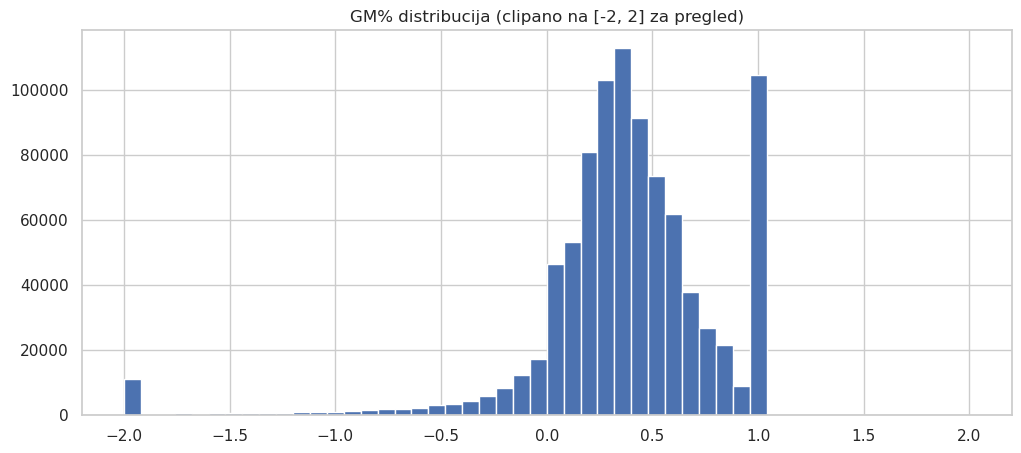

In [31]:
# Provjeri GM% distribuciju
print(df_4['GM%'].describe())
print(f'\nBroj null GM%: {df_4["GM%"].isna().sum()}')
print(f'\nBroj GM% > 1: {(df_4["GM%"] > 1).sum()}')
print(f'Broj GM% < -1: {(df_4["GM%"] < -1).sum()}')
print(f'Broj GM% < -5: {(df_4["GM%"] < -5).sum()}')
print(f'Broj GM% < -10: {(df_4["GM%"] < -10).sum()}')

import matplotlib.pyplot as plt
df_4['GM%'].clip(-2, 2).hist(bins=50)
plt.title('GM% distribucija (clipano na [-2, 2] za pregled)')
plt.show()

In [32]:
# Pogledaj najgore outliere
print('Najmanji GM%:')
display(df_4.nsmallest(10, 'GM%')[['Item Code', 'CustomerID', 'Invoiced price', 'Cost of part', 'GM%']])

print('\nNajveći GM%:')
display(df_4.nlargest(10, 'GM%')[['Item Code', 'CustomerID', 'Invoiced price', 'Cost of part', 'GM%']])

Najmanji GM%:


,Item Code,CustomerID,Invoiced price,Cost of part,GM%
683085,365143TM1,229575,0.0115,52080.1814,-4528710.4261
625878,358421TM1,229575,0.0114,46531.3860,-4081699.5263
715965,F18281-000-AA,108464,0.0100,6205.4715,-620546.1500
715966,F18281-000-AA,108464,0.0100,6205.4715,-620546.1500
908192,360756TM1,229575,0.0114,4653.1386,-408169.0526
577193,356234TM1,229395,0.0100,3098.1000,-309809.0000
183727,363683TM1,222134,0.0118,2174.8684,-184309.8814
1066586,416922TM1,222134,0.0118,2065.4000,-175032.8983
715971,F18281-000-AA,108464,0.0100,1227.8800,-122787.0000
1208323,365096,226113,0.0011,75.3220,-68473.5455



Najveći GM%:


,Item Code,CustomerID,Invoiced price,Cost of part,GM%
711558,2356-168,298276,31.7800,-3718.5738,118.0099
293501,PACA3311912400,2028,15.1700,-52.4300,4.4562
1077256,PACA3311912400,2028,15.1700,-52.1640,4.4386
68870,YB42-F1732-00,2042,1.7850,-2.4658,2.3814
225463,YB42-F1732-00,2042,1.7850,-2.4658,2.3814
519728,YB42-F1732-00,2042,1.7850,-2.4658,2.3814
593567,YB42-F1732-00,2042,1.7850,-2.4658,2.3814
822861,YB42-F1732-00,2042,1.7850,-2.4658,2.3814
906057,YB42-F1732-00,2042,1.7850,-2.4658,2.3814
1006113,YB42-F1732-00,2042,1.7850,-2.4658,2.3814


In [33]:
# Redovi di je cost drastično veći od cijene (npr. 100x+)
suspect = df_4[(df_4['Invoiced price'] > 0) & 
               (df_4['Cost of part'] > df_4['Invoiced price'] * 20)]
print(f"Suspect redova: {len(suspect)}")
print(suspect[['Item Code', 'CustomerID', 'Invoiced price', 'Cost of part', 'GM%']].head(20))

Suspect redova: 1563
             Item Code  CustomerID  Invoiced price  Cost of part      GM%
639            1998-LH      279068          0.0267        0.5820 -20.7978
700        BAR981-RM13        7782          4.6000    12312.6606      NaN
1188    SMA-1033772-06      133704         21.2768     1632.4665      NaN
1601  DEL449-8CH00-238       19421          1.2864       45.1826      NaN
1764            409435      230228          0.3824       18.8741 -48.3570
2347    SMA-1033705-OK      133704          4.7876      137.0608      NaN
2529     HEA383-010818       35098          0.2325        6.8168      NaN
2735  TES-1506323-00-A      258233          0.0771       28.3337      NaN
2752      12-19138-000       17912          0.3500       18.8900 -52.9714
2975    LX6B-S017C10-A       18833          0.2100       10.6750      NaN
3921       SIE-7419902       12629          0.6500      514.6799      NaN
4007        BIO021-657        7800          0.0618      136.9477      NaN
4331       B76-17

In [34]:
# Izbaci garbage data (cost 20x+ veći od cijene)
mask_garbage = (df_4['Invoiced price'] > 0) & (df_4['Cost of part'] > df_4['Invoiced price'] * 20)
print(f"Garbage redova: {mask_garbage.sum()}")
df_4 = df_4[~mask_garbage]

Garbage redova: 1563


In [35]:
df_4['GM%'] = df_4['GM%'].clip(-5, 1)

print('Nakon winsorize:')
print(df_4['GM%'].describe())

Nakon winsorize:
count   899727.0000
mean         0.3590
std          0.5846
min         -5.0000
25%          0.2100
50%          0.3828
75%          0.6046
max          1.0000
Name: GM%, dtype: float64


In [36]:
df_4.to_csv('../data/processed/data_clean_v1.csv', index=False)
print(f'Spremljeno! Shape: {df_4.shape}')

Spremljeno! Shape: (928762, 22)


---
## 5. Popunjavanje nedostajućih vrijednosti

In [37]:
DATE_COLS = [
    'Invoice Date',
    'Customer First Invoice Date'
]
df_5 = pd.read_csv('../data/processed/data_clean_v1.csv', low_memory=False, parse_dates=DATE_COLS)
print(f'Shape: {df_5.shape}')

Shape: (928762, 22)


In [38]:
print(df_5.columns)
df_5.head(10)

Index(['Manufacturing Region', 'Manufacturing Location Code', 'Intercompany',
       'CustomerID', 'Customer industry', 'Customer Region',
       'Customer First Invoice Date', 'Top Customer Group', 'Item Code',
       'Product family', 'Product group', 'Make vs Buy',
       'Sales Channel - Internal', 'Sales Channel - External', 'Invoice Date',
       'Invoice #', 'Invoiced qty (shipped)', 'Ordered qty', 'Invoiced price',
       'Invoiced price (TX)', 'Cost of part', 'GM%'],
      dtype='object')


,Manufacturing Region,Manufacturing Location Code,Intercompany,CustomerID,Customer industry,Customer Region,Customer First Invoice Date,Top Customer Group,Item Code,Product family,Product group,Make vs Buy,Sales Channel - Internal,Sales Channel - External,Invoice Date,Invoice #,Invoiced qty (shipped),Ordered qty,Invoiced price,Invoiced price (TX),Cost of part,GM%
0,North America,N7,NO,230494,IC012,North America,2007-08-08,OTHER,034903,PF002,PC026,BUY,900,900,2019-11-26,16808190,1000.0000,1000.0000,0.1400,0.1400,0.0257,0.8164
1,Asia,N13,NO,223839,IC000,Asia,2003-09-08,OTHER,309146,PF002,PC026,BUY,230,230,2020-03-20,16823988,2000.0000,5000.0000,0.2000,0.2000,0.0000,1.0000
2,Asia,N13,NO,223839,IC000,Asia,2003-09-08,OTHER,309146,PF002,PC026,BUY,230,230,2020-03-20,16818712,1230.0000,5000.0000,0.2000,0.2000,0.0000,1.0000
3,Asia,N13,NO,223839,IC000,Asia,2003-09-08,OTHER,309146,PF002,PC026,BUY,230,230,2020-03-17,16818284,1770.0000,5000.0000,0.2000,0.2000,0.0000,1.0000
4,Asia,N13,NO,224307,IC000,Asia,2011-05-27,OTHER,343372,PF002,SF002,MANUFACTURED,230,230,2018-09-29,16964668,4000.0000,4000.0000,2.7800,2.7800,0.0000,1.0000
5,Asia,N12,NO,224029,IC000,Asia,2005-01-31,OTHER,348716,PF002,PC013,MANUFACTURED,11103,11103,2020-06-15,17028488,15000.0000,15000.0000,2.5800,2.5800,0.0000,1.0000
6,Asia,N12,NO,224029,IC000,Asia,2005-01-31,OTHER,352311,PF002,PC013,MANUFACTURED,11103,11103,2020-01-09,17006210,500.0000,500.0000,2.4700,2.4700,0.0000,1.0000
7,Asia,N13,NO,224600,IC007,Asia,2012-04-10,STAR,357269,PF002,PC013,MANUFACTURED,DG_0029,DG_0029,2019-06-02,16981093,2000.0000,2000.0000,1.8000,1.8000,0.0000,1.0000
8,Asia,N12,NO,231278,IC000,Asia,2005-03-10,OTHER,357314,PF002,PC013,MANUFACTURED,11103,11103,2020-03-20,17011244,500.0000,500.0000,2.2600,2.2600,0.0000,1.0000
9,Asia,N13,NO,223638,IC009,Asia,2018-04-11,OTHER,357325,PF002,PC019,MANUFACTURED,SZ_13748,SZ_13748,2018-08-22,16718215,19.0000,21.0000,248.9996,1705.0000,117.9172,0.5264


In [39]:
results = {}

for col in df_5.columns:
    issues = {}

    null_count = df_5[col].isna().sum()
    if null_count > 0:
        issues['NaN/null'] = null_count

    if df_5[col].dtype == 'object':
        empty_count = (df_5[col] == '').sum()
        if empty_count > 0:
            issues['empty string'] = empty_count

        unknown_count = (df_5[col].str.lower() == 'unknown').sum()
        if unknown_count > 0:
            issues['Unknown'] = unknown_count

        nan_str_count = (df_5[col].str.lower() == 'nan').sum()
        if nan_str_count > 0:
            issues['NaN string'] = nan_str_count

    if issues:
        results[col] = issues

for col, issues in results.items():
    total = sum(issues.values())
    print(f'\n{col} (ukupno: {total})')
    for issue_type, count in issues.items():
        print(f'{issue_type}: {count}')


Manufacturing Region (ukupno: 21147)
NaN/null: 21147

Manufacturing Location Code (ukupno: 20640)
NaN/null: 20640

Customer Region (ukupno: 62)
NaN/null: 62

Product group (ukupno: 43730)
NaN/null: 43730

Make vs Buy (ukupno: 3005)
NaN/null: 3005

Sales Channel - Internal (ukupno: 20868)
NaN/null: 20868

Sales Channel - External (ukupno: 20868)
NaN/null: 20868

Ordered qty (ukupno: 23170)
NaN/null: 23170

Cost of part (ukupno: 19781)
NaN/null: 19781

GM% (ukupno: 29035)
NaN/null: 29035


In [40]:
# Zamijeni prazne stringove s NaN za konzistentnost
df_5 = df_5.replace('', np.nan)

# Kategorički stupci — popuni s 'Unknown'
fill_unknown = [
    'Manufacturing Region',
    'Manufacturing Location Code',
    'Intercompany',
    'Customer industry',
    'Customer Region',
    'Top Customer Group',
    'Product family',
    'Product group',
    'Make vs Buy',
    'Sales Channel - Internal',
    'Sales Channel - External'
]

for col in fill_unknown:
    if col in df_5.columns:
        n_filled = df_5[col].isna().sum()
        df_5[col] = df_5[col].fillna('Unknown')
        if n_filled > 0:
            print(f'{col}: popunjeno {n_filled} redova s "Unknown"')

Manufacturing Region: popunjeno 21147 redova s "Unknown"
Manufacturing Location Code: popunjeno 20640 redova s "Unknown"
Customer Region: popunjeno 62 redova s "Unknown"
Product group: popunjeno 43730 redova s "Unknown"
Make vs Buy: popunjeno 3005 redova s "Unknown"
Sales Channel - Internal: popunjeno 20868 redova s "Unknown"
Sales Channel - External: popunjeno 20868 redova s "Unknown"


In [41]:
results = {}

for col in df_5.columns:
    issues = {}

    null_count = df_5[col].isna().sum()
    if null_count > 0:
        issues['NaN/null'] = null_count

    if df_5[col].dtype == 'object':
        empty_count = (df_5[col] == '').sum()
        if empty_count > 0:
            issues['empty string'] = empty_count

        unknown_count = (df_5[col].str.lower() == 'unknown').sum()
        if unknown_count > 0:
            issues['Unknown'] = unknown_count

        nan_str_count = (df_5[col].str.lower() == 'nan').sum()
        if nan_str_count > 0:
            issues['NaN string'] = nan_str_count

    if issues:
        results[col] = issues

for col, issues in results.items():
    total = sum(issues.values())
    print(f'\n{col} (ukupno: {total})')
    for issue_type, count in issues.items():
        print(f'{issue_type}: {count}')


Manufacturing Region (ukupno: 21147)
Unknown: 21147

Manufacturing Location Code (ukupno: 20640)
Unknown: 20640

Customer Region (ukupno: 62)
Unknown: 62

Product group (ukupno: 43730)
Unknown: 43730

Make vs Buy (ukupno: 3005)
Unknown: 3005

Sales Channel - Internal (ukupno: 20868)
Unknown: 20868

Sales Channel - External (ukupno: 20868)
Unknown: 20868

Ordered qty (ukupno: 23170)
NaN/null: 23170

Cost of part (ukupno: 19781)
NaN/null: 19781

GM% (ukupno: 29035)
NaN/null: 29035


In [42]:
n_before = df_5['Cost of part'].isna().sum()
print(f'Cost of part null: {n_before} redova')

Cost of part null: 19781 redova


In [43]:
# Koliko Item Code-ova ima ISKLJUČIVO null Cost of part?
null_items = df_5.groupby('Item Code')['Cost of part'].apply(lambda x: x.isna().all())
print(f"Item Code-ovi gdje su SVI Cost of part null: {null_items.sum()}")
print(f"Ukupno redova u tim grupama: {df_5[df_5['Item Code'].isin(null_items[null_items].index)].shape[0]}")
# dakle svi koji imaju null cost of part nemaju nigdje drugdje neki cost of part

Item Code-ovi gdje su SVI Cost of part null: 1367
Ukupno redova u tim grupama: 19781


In [44]:
# Imaju li redovi bez Cost of part uopće smisleni GM%?
mask = df_5['Cost of part'].isna()
print(df_5.loc[mask, 'GM%'].describe())
print(df_5["Product group"].nunique())
print(df_5["Item Code"].nunique())

count   0.0000
mean       NaN
std        NaN
min        NaN
25%        NaN
50%        NaN
75%        NaN
max        NaN
Name: GM%, dtype: float64
32
51954


In [45]:
# Ćelija 1: Imputacija GM% gdje imamo Price i Cost
n_before = df_5['GM%'].isna().sum()

mask = df_5['GM%'].isna() & df_5['Cost of part'].notna() & (df_5['Invoiced price'] != 0)
df_5.loc[mask, 'GM%'] = (df_5.loc[mask, 'Invoiced price'] - df_5.loc[mask, 'Cost of part']) / df_5.loc[mask, 'Invoiced price']

n_after = df_5['GM%'].isna().sum()
print(f'GM% popunjeno: {n_before - n_after} redova')
print(f'GM% još null: {n_after}')

GM% popunjeno: 9254 redova
GM% još null: 19781


In [46]:
# Ćelija 2: Provjera outliera
print(df_5['GM%'].describe())
print(f'\nGM% < -5: {(df_5["GM%"] < -5).sum()}')
print(f'GM% > 1: {(df_5["GM%"] > 1).sum()}')
print(f'GM% < -1: {(df_5["GM%"] < -1).sum()}')
print(f'GM% < 0: {(df_5["GM%"] < 0).sum()}')

count    908981.0000
mean          5.5114
std        4279.3611
min         -18.6859
25%           0.2106
50%           0.3840
75%           0.6077
max     4075221.9019
Name: GM%, dtype: float64

GM% < -5: 126
GM% > 1: 412
GM% < -1: 16250
GM% < 0: 78472


In [47]:
# Ćelija 3: Winsorize (nakon što vidiš rezultate ćelije 2, prilagodi granice)
df_5['GM%'] = df_5['GM%'].clip(-5, 1)
print(df_5['GM%'].describe())

count   908981.0000
mean         0.3603
std          0.5882
min         -5.0000
25%          0.2106
50%          0.3840
75%          0.6077
max          1.0000
Name: GM%, dtype: float64


In [48]:
still_null_gm = df_5[df_5['GM%'].isna()]

print(f'Invoiced price null u tim redovima: {still_null_gm["Invoiced price"].isna().sum()}')
print(f'Cost of part null u tim redovima: {still_null_gm["Cost of part"].isna().sum()}')
print(f'Invoiced price == 0 u tim redovima: {(still_null_gm["Invoiced price"] == 0).sum()}')

Invoiced price null u tim redovima: 0
Cost of part null u tim redovima: 19781
Invoiced price == 0 u tim redovima: 0


In [49]:
print(f'GM% null ostavljamo: {df_5["GM%"].isna().sum()}')
print(f'To je {df_5["GM%"].isna().sum() / len(df_5) * 100:.1f}% dataseta')

GM% null ostavljamo: 19781
To je 2.1% dataseta


In [50]:
# Spremi čist dataset
df_5.to_csv('../data/processed/data_clean_final.csv', index=False)
print(f'Spremljeno: {df_5.shape}')
print(f'Stupci: {df_5.columns.tolist()}')

Spremljeno: (928762, 22)
Stupci: ['Manufacturing Region', 'Manufacturing Location Code', 'Intercompany', 'CustomerID', 'Customer industry', 'Customer Region', 'Customer First Invoice Date', 'Top Customer Group', 'Item Code', 'Product family', 'Product group', 'Make vs Buy', 'Sales Channel - Internal', 'Sales Channel - External', 'Invoice Date', 'Invoice #', 'Invoiced qty (shipped)', 'Ordered qty', 'Invoiced price', 'Invoiced price (TX)', 'Cost of part', 'GM%']


---
## Sažetak — što smo napravili

| Korak | Akcija |
|-------|--------|
| Stupci | Uklonili smo 11 redudantnih stupaca (cleaner.py) |
| Intercompany | Filtrirali smo Intercompany=YES transakcije van modela |
| Redovi | Uklonili smo redove bez Item Code / CustomerID / Invoiced price |
| Redovi | Uklonili smo negativne cijene i količine (credit note-ovi) |
| GM% | Winsorized na [-5, 1] za outliere |
| Nullovi | Kategorički → 'Unknown', numerički → medijan |